# Da punteggi a percentuali, e come si misura una previsione

*Anatomia di un LLM* · capitolo 3, I mattoni · script `01-07`, `scripts/01_07_softmax_entropia.py`

Il modello produce punteggi senza scala. La softmax li trasforma in
percentuali che sommano a uno, e la temperatura decide quanto quelle
percentuali siano nette. Poi serve un numero che dica se la previsione era
buona: e' la perdita che vedremo scendere per tutto il capitolo 5.

Si esegue con `python3 scripts/01_07_softmax_entropia.py`
e dura circa 5 secondi.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/01_07_softmax_entropia.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [ ]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [ ]:
import math

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch

from llm_anatomy.utils import figura, prepara, stile_figure, titolo, verifica

prepara()

logits = torch.tensor([2.0, 1.0, 0.5, -1.0, -2.0])
etichette = ["il", "un", "questo", "gatto", "xkq"]

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337


In [ ]:
titolo("Da punteggi a percentuali")
p = logits.softmax(dim=-1)
print(f"  {'simbolo':<10} {'logit':>8} {'exp':>10} {'prob':>8}")
for e, l, pi in zip(etichette, logits.tolist(), p.tolist()):
    print(f"  {e:<10} {l:8.2f} {math.exp(l):10.3f} {pi:8.4f}")
verifica(abs(p.sum().item() - 1.0) < 1e-6, "le probabilita' sommano a uno")


Da punteggi a percentuali
-------------------------
  simbolo       logit        exp     prob
  il             2.00      7.389   0.6027
  un             1.00      2.718   0.2217
  questo         0.50      1.649   0.1345
  gatto         -1.00      0.368   0.0300
  xkq           -2.00      0.135   0.0110
  [verifica superata] le probabilita' sommano a uno


In [ ]:
titolo("Aggiungere lo stesso a tutti non cambia niente")
spostati = logits + 100.0
verifica(torch.allclose(spostati.softmax(-1), p, atol=1e-6),
         "sommare una costante a tutti i logit non cambia la distribuzione")
print("  per questo l'implementazione sottrae il massimo prima di esponenziare:")
print(f"  exp(100 + 2) = {math.exp(102):.3e} traboccherebbe in float32 gia' a ~88")


def entropia(prob: torch.Tensor) -> float:
    prob = prob[prob > 0]
    return float(-(prob * prob.log()).sum())


Aggiungere lo stesso a tutti non cambia niente
----------------------------------------------
  [verifica superata] sommare una costante a tutti i logit non cambia la distribuzione
  per questo l'implementazione sottrae il massimo prima di esponenziare:
  exp(100 + 2) = 1.986e+44 traboccherebbe in float32 gia' a ~88


In [ ]:
titolo("La temperatura: quanto essere decisi")
print(f"  {'T':>6} {'prob del massimo':>18} {'entropia (nat)':>16} "
      f"{'perplexity':>12}")
temperature = [0.25, 0.5, 1.0, 2.0, 5.0]
entropie = []
for t in temperature:
    q = (logits / t).softmax(dim=-1)
    h = entropia(q)
    entropie.append(h)
    print(f"  {t:6.2f} {q.max().item():18.4f} {h:16.4f} {math.exp(h):12.2f}")
print(f"  limite T -> 0: distribuzione concentrata, entropia 0")
print(f"  limite T -> inf: uniforme, entropia log(5) = {math.log(5):.4f}")
verifica(entropie[0] < entropie[-1],
         "l'entropia cresce al crescere della temperatura")


La temperatura: quanto essere decisi
------------------------------------
       T   prob del massimo   entropia (nat)   perplexity
    0.25             0.9796           0.1070         1.11
    0.50             0.8418           0.5406         1.72
    1.00             0.6027           1.0639         2.90
    2.00             0.4103           1.4091         4.09
    5.00             0.2811           1.5712         4.81
  limite T -> 0: distribuzione concentrata, entropia 0
  limite T -> inf: uniforme, entropia log(5) = 1.6094
  [verifica superata] l'entropia cresce al crescere della temperatura


In [ ]:
titolo("Misurare quanto una previsione e' incerta")
casi = {
    "quasi certa": torch.tensor([10.0, 0.0, 0.0, 0.0, 0.0]),
    "il caso sopra": logits,
    "uniforme": torch.zeros(5),
}
for nome, l in casi.items():
    q = l.softmax(dim=-1)
    h = entropia(q)
    print(f"  {nome:<15} entropia {h:.4f} nat   perplexity {math.exp(h):6.2f}   "
          f"prob max {q.max():.3f}")


Misurare quanto una previsione e' incerta
-----------------------------------------
  quasi certa     entropia 0.0020 nat   perplexity   1.00   prob max 1.000
  il caso sopra   entropia 1.0639 nat   perplexity   2.90   prob max 0.603
  uniforme        entropia 1.6094 nat   perplexity   5.00   prob max 0.200



Il numero che diremo perdita
----------------------------
  quasi certa     -log p(bersaglio) = 0.0002   perplexity     1.00
  il caso sopra   -log p(bersaglio) = 0.5063   perplexity     1.66
  uniforme        -log p(bersaglio) = 1.6094   perplexity     5.00
  un modello a caso su 93 simboli parte da una perdita di 4.533
  ed e' esattamente il valore da cui parte il mini-modello nel Cap. 5


  [figura] outputs/figures/01-07_temperatura_entropia.pdf


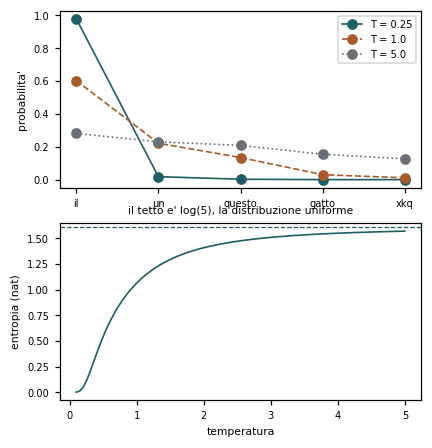

In [ ]:
titolo("Il numero che diremo perdita")
bersaglio = 0
for nome, l in casi.items():
    q = l.softmax(dim=-1)
    ce = -math.log(float(q[bersaglio]))
    print(f"  {nome:<15} -log p(bersaglio) = {ce:.4f}   "
          f"perplexity {math.exp(ce):8.2f}")
print("  un modello a caso su 93 simboli parte da una perdita di "
      f"{math.log(93):.3f}")
print("  ed e' esattamente il valore da cui parte il mini-modello nel Cap. 5")

fig, ax = plt.subplots(2, 1, figsize=(stile_figure(), 4.6))
x = torch.arange(5)
for t in (0.25, 1.0, 5.0):
    ax[0].plot(x, (logits / t).softmax(-1), marker="o", label=f"T = {t}")
ax[0].set_xticks(x, etichette)
ax[0].set_ylabel("probabilita'")
ax[0].legend()
tt = torch.linspace(0.1, 5, 100)
ax[1].plot(tt, [entropia((logits / float(t)).softmax(-1)) for t in tt])
ax[1].axhline(math.log(5), ls="--", lw=0.8)
ax[1].set_xlabel("temperatura")
ax[1].set_ylabel("entropia (nat)")
ax[1].set_title("il tetto e' log(5), la distribuzione uniforme")
figura(fig, "01-07_temperatura_entropia")

## Da provare

prova temperatura 0,1 e 5,0 sugli stessi logit.